# Manhattan Plot

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Plots −log10 p for every genetic variant against its genomic position, chromosome by chromosome. Association signals stand out as 'skyscrapers' above a genome-wide significance line.

## When to use

- Show genome-wide association studies (GWAS) or epigenome-wide scans
- Show any long, ordered sequence of tests where the location of strong signals matters

## Avoid when

- There are few tests (use a volcano or forest plot)
- Position along the x-axis has no meaning

## Alternatives

- Q-Q plot of p-values (checks inflation)
- Regional association plot (zoom in)

## Design tips

- Alternate two shades of one hue by chromosome and use an accent color for significant hits
- Draw the genome-wide (5×10⁻⁸) and suggestive (1×10⁻⁵) thresholds

## Example

A synthetic GWAS of 40,000 SNPs across 22 autosomes with three true association peaks.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(5)
chrom_len = np.array([249, 242, 198, 190, 181, 171, 159, 145, 138, 134, 135,
                      133, 114, 107, 102, 90, 83, 80, 59, 64, 47, 51])  # Mb
n_snp = (chrom_len / chrom_len.sum() * 40000).astype(int)
chrom = np.repeat(np.arange(1, 23), n_snp)
pos = np.concatenate([np.sort(rng.uniform(0, L, k)) for L, k in zip(chrom_len, n_snp)])
nlp = -np.log10(rng.uniform(size=len(chrom)))
for c, center, height in [(2, 120, 14), (6, 32, 22), (16, 54, 9.5)]:
    m = chrom == c
    nlp[m] += height * np.exp(-((pos[m] - center) / 0.8) ** 2) * rng.uniform(0.6, 1, m.sum())
df = pd.DataFrame({"chrom": chrom, "pos_mb": pos, "nlp": nlp})
offsets = np.r_[0, np.cumsum(chrom_len)[:-1]]
df["x"] = df.pos_mb + offsets[df.chrom - 1]
df.head()

,chrom,pos_mb,nlp,x
0,1,0.000339,1.102399,0.000339
1,1,0.040324,0.062090,0.040324
2,1,0.229027,0.035541,0.229027
3,1,0.249269,0.666483,0.249269
4,1,0.293134,0.047455,0.293134


### Plot

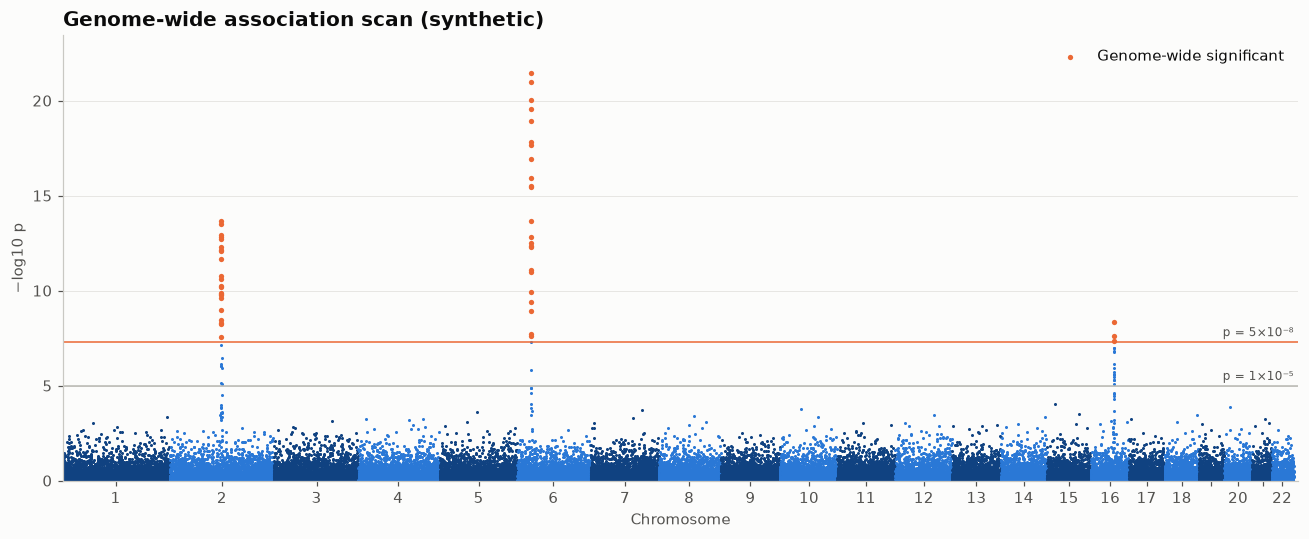

In [3]:
gw, sug = -np.log10(5e-8), -np.log10(1e-5)
fig, ax = plt.subplots(figsize=(12, 5))
shades = [PALETTE[0], "#104281"]
for c, d in df.groupby("chrom"):
    ax.scatter(d.x, d.nlp, s=4, color=shades[c % 2], linewidth=0)
hit = df[df.nlp > gw]
ax.scatter(hit.x, hit.nlp, s=12, color=PALETTE[1], linewidth=0, label="Genome-wide significant")
ax.axhline(gw, color=PALETTE[1], linewidth=1)
ax.axhline(sug, color=GRAY, linewidth=1)
ax.text(df.x.max(), gw + 0.3, "p = 5×10⁻⁸", ha="right", fontsize=8, color="#52514e")
ax.text(df.x.max(), sug + 0.3, "p = 1×10⁻⁵", ha="right", fontsize=8, color="#52514e")
centers = df.groupby("chrom").x.median()
ax.set_xticks(centers, [str(c) if c < 18 or c % 2 == 0 else "" for c in centers.index])
ax.set_xlim(0, df.x.max() + 10); ax.set_ylim(0, df.nlp.max() + 2)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Chromosome"); ax.set_ylabel("−log10 p")
ax.set_title("Genome-wide association scan (synthetic)")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## How to read it

Each dot is a SNP. The tall towers on chromosomes 2, 6 and 16 cross the genome-wide line and are loci associated with the trait.

---
Standalone script: [`manhattan_plot.py`](manhattan_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)